# Performance Analysis: Gold M vs Predicted M (Both Optuna Tuned)

This notebook compares two best-in-class models to analyze the impact of idiom signal prediction quality on ranking performance.

1. **Gold Tuned**: The theoretical upper bound (uses ground-truth signals).
2. **Predicted Tuned**: The real-world performance (uses LLM-predicted signals).

Gold vs Predicted Comparison:


,Model,Dev nDCG,Test nDCG,Test Top-1,Xeval nDCG
0,Optuna (Gold M),88.97,81.79,40.00,81.66
1,Optuna (Pred M),79.37,78.07,30.63,74.72


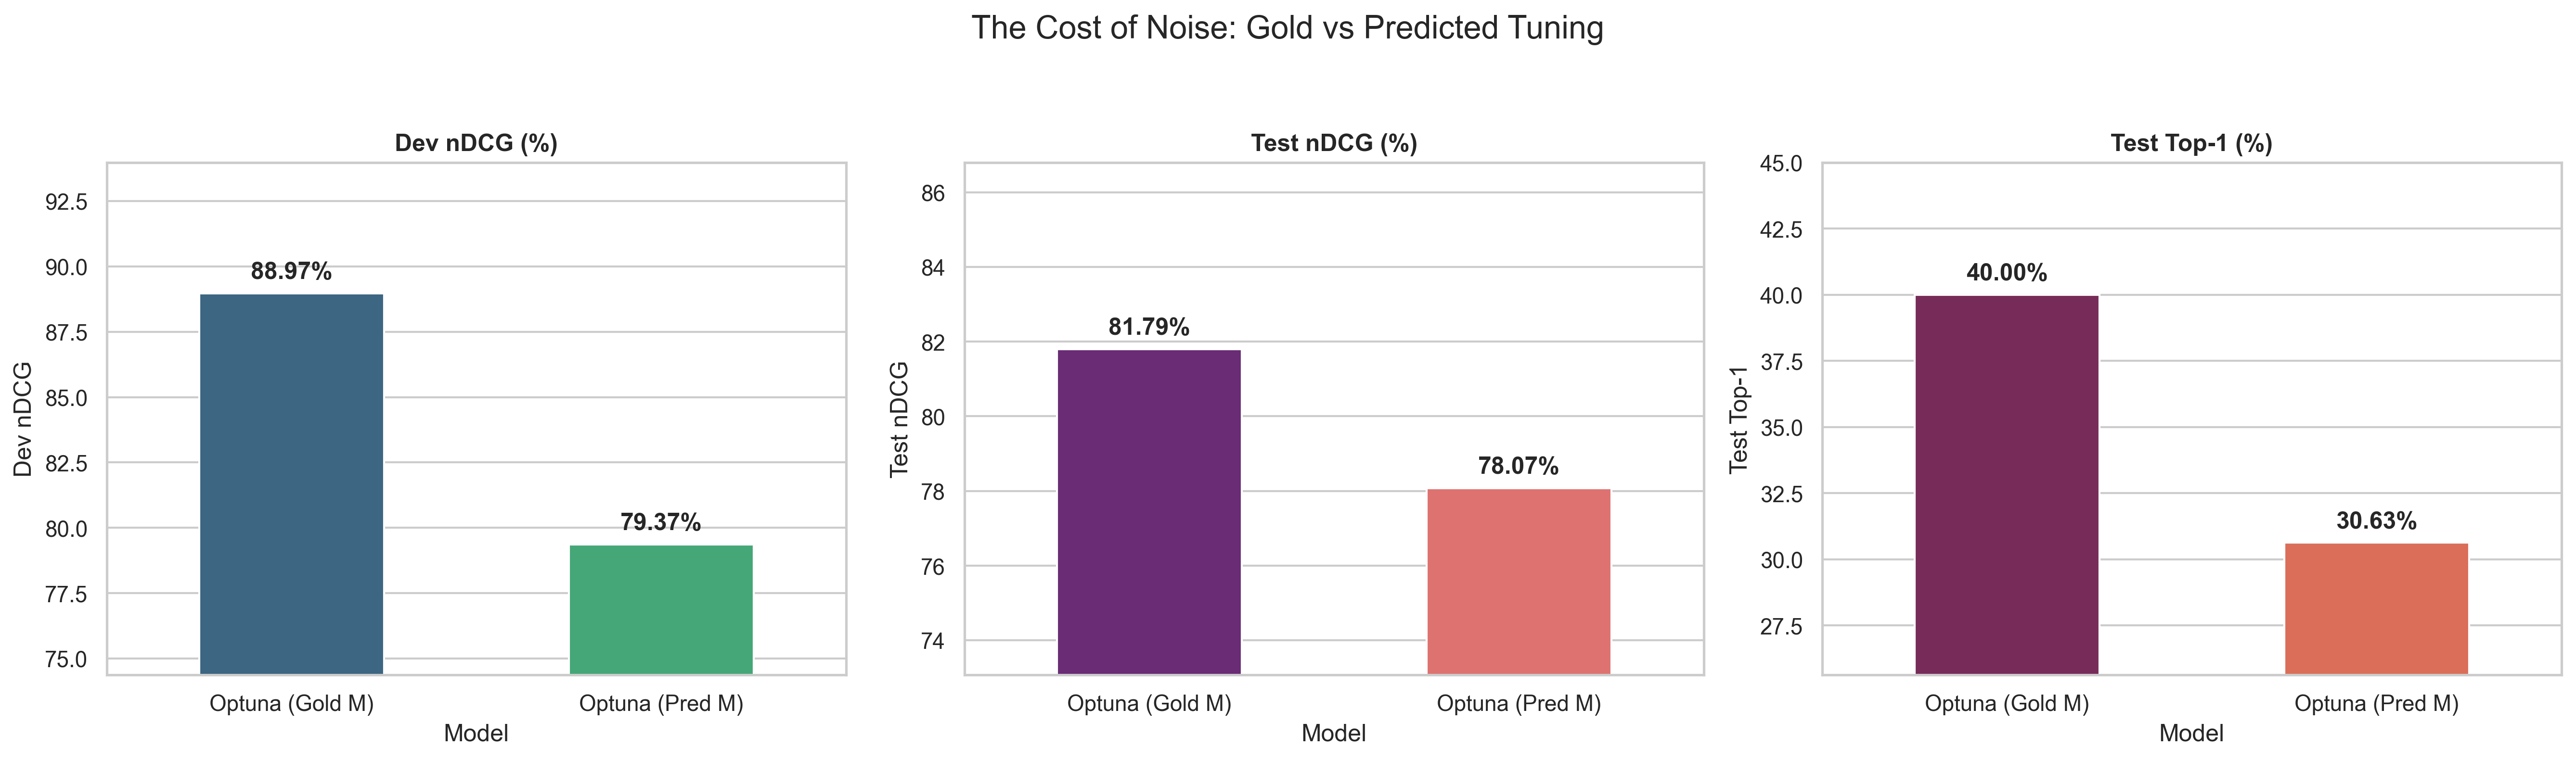

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use('default')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 300

def load_summary(path_str):
    path = Path(path_str)
    if path.exists():
        with open(path, 'r') as f:
            return json.load(f)
    return None

base_dir = Path('..')
paths = {
    'Optuna (Gold M)': base_dir / 'hyperparam_tuning/final_model/summary.json',
    'Optuna (Pred M)': base_dir / 'tuning_predicted/final_model/summary.json'
}

data = {}
for name, path in paths.items():
    summary = load_summary(path)
    if summary:
        data[name] = summary['aggregate'][0]
        
if len(data) == 2:
    rows = []
    for name, agg in data.items():
        rows.append({
            'Model': name,
            'Dev nDCG': agg['best_dev']['ndcg'] * 100,
            'Test nDCG': agg['test']['ndcg'] * 100,
            'Test Top-1': agg['test']['top1'] * 100,
            'Xeval nDCG': agg['xeval']['ndcg'] * 100,
        })
        
    df = pd.DataFrame(rows)
    print("Gold vs Predicted Comparison:")
    display(df.round(2))
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    metrics = [('Dev nDCG', 'viridis'), ('Test nDCG', 'magma'), ('Test Top-1', 'rocket')]
    
    for i, (metric, cmap) in enumerate(metrics):
        ax = axes[i]
        sns.barplot(data=df, x='Model', y=metric, hue='Model', legend=False, palette=cmap, width=0.5, ax=ax)
        ymin, ymax = df[metric].min() - 5, df[metric].max() + 5
        ax.set_ylim(max(0, ymin), min(100, ymax))
        ax.set_title(f'{metric} (%)', fontweight='bold')
        for p in ax.patches:
            ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontweight='bold')
                     
    plt.suptitle("The Cost of Noise: Gold vs Predicted Tuning", fontsize=16, y=1.05)
    plt.tight_layout()
    plt.show()
else:
    print("Could not load data. Ensure both tuning experiments are finished.")